# 02 — Lineer Regresyon ile Yangın Duyarlılık Skoru Tahmini

**Veri künyesi:** Eriş (2026), Mendeley Data, doi:10.17632/mjz29dh3g8.1 (CC BY 4.0) · Muğla ili, 2015–2024 yangın kayıtları · temizlik sonrası 6410 nokta · bir satır = bir örnek nokta
**Hedef:** regresyonda yangın duyarlılık skoru (0/1 hedefin olasılık tahmini, `Yangin`), sınıflandırmada `Sinif` (Yangın Yok / Yangın)
**Özellikler (16):** topografya (yükseklik, eğim, bakının sin/cos bileşenleri, düz alan); iklim (yıllık ortalama sıcaklık, aylık ortalama yağış, rüzgâr hızı); bitki örtüsü (NDVI, dört arazi örtüsü göstergesi, referans: orman); insan etkisi (yola, yerleşime ve akarsuya uzaklık)
**Bölünme:** sınıfa göre katmanlı rastgele %80 eğitim / %20 test · güvenilirlik sınaması: eğitim kümesinde 5 katlı sözde mekânsal grup doğrulaması (25 iklim grubu)
**Tekrar üretilebilirlik:** bütün rastgelelikler tek tohuma (`random_state = 42`) bağlıdır; notebook baştan çalıştırıldığında aynı sayılar elde edilir.

Lineer regresyon, hedef değişkeni özelliklerin doğrusal bir bileşimi olarak modeller.
Katsayıları, hata kareleri toplamını en aza indirecek biçimde (en küçük kareler)
çözer. Hedef 0/1 olduğunda bu modele **doğrusal olasılık modeli** denir: tahmin, bir
noktanın yangın noktası olma olasılığının doğrusal bir yaklaşımıdır. Tahminler 0–1
aralığının dışına taşabilir; bu, yöntemin bilinen bir zaafıdır ve lojistik regresyonun
neden geliştirildiğini de açıklar. En yalın regresyon yöntemi olduğu için diğer bütün
regresyon modellerine referans oluşturur: karmaşık bir model bu çizgiyi belirgin
biçimde geçemiyorsa, veride yakalanabilir doğrusal olmayan bir sinyal yok demektir.

## 1. Veri Hazırlığı

In [1]:
import ortak as o
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression

df = o.veri_yukle()
X_tr, X_te, yr_tr, yr_te, yc_tr, yc_te = o.bolunme(df)
tb = o.taban_cizgileri(df)
print(f"Eğitim: {len(X_tr)} nokta  |  Test: {len(X_te)} nokta")
print("Özellikler:", o.OZELLIKLER)

6410 nokta · yangın 3144 · yangın yok 3266
Eğitim: 5128 nokta  |  Test: 1282 nokta
Özellikler: ['Yukseklik', 'Egim', 'Baki_Sin', 'Baki_Cos', 'Baki_Duz', 'Sicaklik', 'Yagis', 'Ruzgar_Hizi', 'NDVI', 'Arazi_Tarim', 'Arazi_Calilik', 'Arazi_Yerlesim', 'Arazi_Su_Ciplak', 'Yol_Uzaklik', 'Yerlesim_Uzaklik', 'Akarsu_Uzaklik']


## 2. Model Eğitimi ve Test Performansı

In [2]:
model = LinearRegression()
model.fit(X_tr, yr_tr)
y_pred = model.predict(X_te)

reg = o.reg_metrikleri(yr_te, y_pred)
print("Test kümesi metrikleri")
print("-" * 34)
for k, v in reg.items():
    print(f"{k:>6}: {v:.4f}")
disari = float(((y_pred < 0) | (y_pred > 1)).mean())
print(f"\n0–1 aralığının dışına taşan tahmin oranı: %{disari * 100:.1f}")

print("\nÖğrenilen denklem (ham birimlerle):")
terimler = " + ".join(f"({c:+.6f} × {ad})" for c, ad in zip(model.coef_, o.OZELLIKLER))
print(f"  Skor = {model.intercept_:.4f} + {terimler}")

Test kümesi metrikleri
----------------------------------
   MAE: 0.3568
   MSE: 0.1714
  RMSE: 0.4140
    R2: 0.3142
   AUC: 0.8288

0–1 aralığının dışına taşan tahmin oranı: %6.9

Öğrenilen denklem (ham birimlerle):
  Skor = 0.4229 + (-0.000104 × Yukseklik) + (-0.004901 × Egim) + (+0.020760 × Baki_Sin) + (-0.023373 × Baki_Cos) + (-0.047516 × Baki_Duz) + (+0.035744 × Sicaklik) + (+0.001320 × Yagis) + (-0.150679 × Ruzgar_Hizi) + (+0.464365 × NDVI) + (-0.024436 × Arazi_Tarim) + (-0.228034 × Arazi_Calilik) + (+0.126125 × Arazi_Yerlesim) + (-0.286902 × Arazi_Su_Ciplak) + (-0.000020 × Yol_Uzaklik) + (-0.000020 × Yerlesim_Uzaklik) + (-0.000068 × Akarsu_Uzaklik)


### 2.1 Taban Çizgileriyle Karşılaştırma

Regresyonda iki taban kullanılır. **Ortalama tabanı** her test noktasına eğitim
kümesinin yangın oranını atar; R² = 0 ve AUC = 0,5 bu tabana karşılık gelir. **Tek kural
tabanı** ise eğitim kümesinden öğrenilmiş tek bir eşik sorusunun iki yanındaki yangın
oranlarını tahmin eder. Bir modelin işe yaradığını söyleyebilmek için asıl geçilmesi
gereken çizgi tek kuraldır.

In [3]:
print(f"Ortalama tabanı: eğitim kümesinin yangın oranı = {tb['egitim_yangin_orani']:.4f}")
print(f"  {'Ölçüt':>6} | {'model':>8} | {'ortalama':>8} | {'tek kural':>9} | tek kurala göre fark")
for k in reg:
    fark = reg[k] - tb["kural_regresyon"][k]
    yorum = "iyi" if (k in o.BUYUK_IYI and fark > 0) or (k not in o.BUYUK_IYI and fark < 0) else "kötü"
    print(f"  {k:>6} | {reg[k]:8.4f} | {tb['regresyon'][k]:8.4f} | "
          f"{tb['kural_regresyon'][k]:9.4f} | {fark:+.4f} ({yorum})")

Ortalama tabanı: eğitim kümesinin yangın oranı = 0.4904
   Ölçüt |    model | ortalama | tek kural | tek kurala göre fark
     MAE |   0.3568 |   0.4998 |    0.3931 | -0.0362 (iyi)
     MSE |   0.1714 |   0.2499 |    0.1978 | -0.0264 (iyi)
    RMSE |   0.4140 |   0.4999 |    0.4447 | -0.0307 (iyi)
      R2 |   0.3142 |  -0.0000 |    0.2086 | +0.1056 (iyi)
     AUC |   0.8288 |   0.5000 |    0.6982 | +0.1306 (iyi)


In [4]:
o.reg_grafikleri(yr_te, y_pred, "Lineer Regresyon", "lineer")

'C:\\Users\\BALTRON\\Desktop\\kitapdeprem\\kitapdeprem\\ORMAN YANGINI\\sekiller\\lineer_regresyon.png'

## 3. Algoritmaya Özgü Analiz: Standartlaştırılmış Katsayılar

Ham katsayılar özelliklerin birimine bağlıdır (yükseklik metre, uzaklıklar metre,
sıcaklık °C, NDVI birimsizdir) ve doğrudan karşılaştırılamaz. Bu nedenle aynı model
standartlaştırılmış özelliklerle bir kez daha kurulur. Tahminler değişmez; yalnızca
katsayılar "bir standart sapmalık artış, yangın duyarlılık skorunu ne kadar değiştirir?"
sorusunun cevabına dönüşür.

İki modelin tahminleri arasındaki en büyük fark: 1.95e-14 (sayısal yuvarlama)


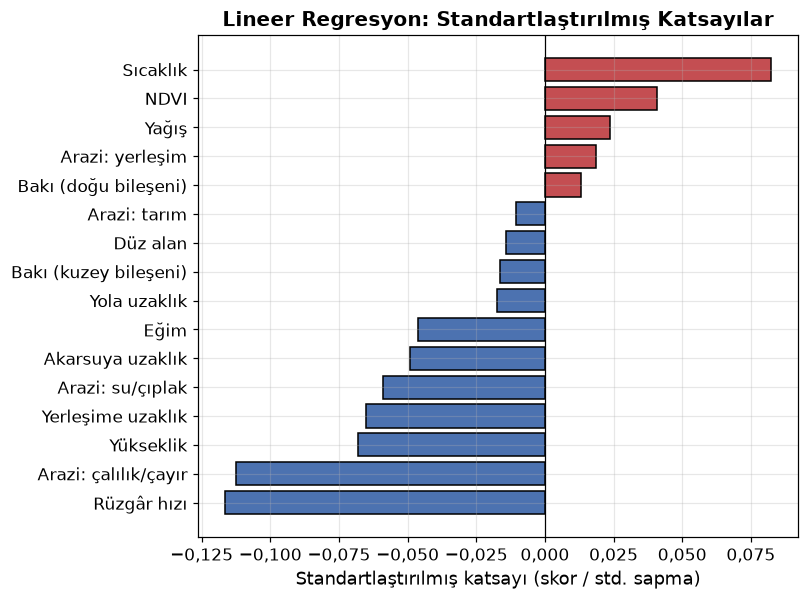

Ruzgar_Hizi        -0.116
Arazi_Calilik      -0.113
Sicaklik            0.082
Yukseklik          -0.068
Yerlesim_Uzaklik   -0.065
Arazi_Su_Ciplak    -0.059
Akarsu_Uzaklik     -0.049
Egim               -0.046
NDVI                0.041
Yagis               0.024
Arazi_Yerlesim      0.018
Yol_Uzaklik        -0.017
Baki_Cos           -0.017
Baki_Duz           -0.014
Baki_Sin            0.013
Arazi_Tarim        -0.010


In [5]:
X_tr_s, X_te_s = o.olcekli(X_tr, X_te)
std_model = LinearRegression().fit(X_tr_s, yr_tr)
fark_tahmin = float(np.max(np.abs(std_model.predict(X_te_s) - y_pred)))
print(f"İki modelin tahminleri arasındaki en büyük fark: {fark_tahmin:.2e} (sayısal yuvarlama)")
std_katsayi = pd.Series(std_model.coef_, index=o.OZELLIKLER)

s = std_katsayi.rename(index=o.OKUNUR).sort_values()
fig, ax = plt.subplots(figsize=(7.5, 5.6))
ax.barh(s.index, s.values, color=["#4c72b0" if v < 0 else "#c44e52" for v in s.values], edgecolor="k")
ax.axvline(0, color="k", lw=0.8)
ax.set_xlabel("Standartlaştırılmış katsayı (skor / std. sapma)")
ax.set_title("Lineer Regresyon: Standartlaştırılmış Katsayılar")
fig.tight_layout()
fig.savefig(os.path.join(o.SEKIL_DIR, "lineer_onem.png"), bbox_inches="tight")
plt.show()
print(std_katsayi.sort_values(key=np.abs, ascending=False).round(3).to_string())

## Güvenilirlik Sınaması: Sözde Mekânsal Grup Katlamalı Doğrulama

Rastgele bölünmede bir test noktasının hemen yanındaki noktalar eğitimde kalır; bu
noktalar neredeyse aynı iklim, yükseklik ve arazi değerlerini taşıdığı için model test
noktasını "komşusundan ezberleyerek" doğru bilebilir. Veri setinde koordinat olmadığından
konumun yerine iklim yüzeyleri kullanılır: noktalar sıcaklık, yağış ve rüzgâr değerlerine
göre 25 gruba ayrılmıştır ve her grup yaklaşık bir bölgeye karşılık gelir. Aşağıdaki döngü
yalnızca **eğitim kümesini** kullanır ve 5 kat kurar; her katta bazı gruplar **bütünüyle**
dışarıda bırakılır ve model hiç görmediği bu bölgelerde sınanır. Test kümesine bu döngüde
hiç dokunulmaz. Rastgele test sonucu ile bu sınamanın sonucu arasındaki fark, ana
sonuçlardaki iyimserliğin ölçüsüdür.

In [6]:
import numpy as np

cv_r2, cv_f1, cv_yil = [], [], []
for kat, Xa, Xb, yra, yrb, ysa, ysb in o.cv_katlari(df):
    r_tahmin = LinearRegression().fit(Xa, yra).predict(Xb)
    cv_r2.append(o.reg_metrikleri(yrb, r_tahmin)["R2"])
    cv_f1.append(float("nan"))  # bu algoritma sınıflandırma yapmaz
    cv_yil.append(kat)
    print(f"  kat {kat}: eğitim {len(Xa):5d} · sınama {len(Xb):5d}"
          f" · R² {cv_r2[-1]:+.4f} · F1-makro {cv_f1[-1]:.4f}")

cv_r2, cv_f1 = np.array(cv_r2, dtype=float), np.array(cv_f1, dtype=float)
print("Sözde mekânsal grup doğrulaması (5 kat)")
print(f"  R²      : {np.nanmean(cv_r2):+.4f} ± {np.nanstd(cv_r2):.4f}")
print(f"  F1-makro: {np.nanmean(cv_f1):.4f} ± {np.nanstd(cv_f1):.4f}")
cv_ozet = {"katlar": cv_yil, "R2": [None if np.isnan(v) else float(v) for v in cv_r2],
           "F1_macro": [None if np.isnan(v) else float(v) for v in cv_f1],
           "R2_ort": None if np.all(np.isnan(cv_r2)) else float(np.nanmean(cv_r2)),
           "R2_std": None if np.all(np.isnan(cv_r2)) else float(np.nanstd(cv_r2)),
           "F1_ort": None if np.all(np.isnan(cv_f1)) else float(np.nanmean(cv_f1)),
           "F1_std": None if np.all(np.isnan(cv_f1)) else float(np.nanstd(cv_f1))}


  kat 1: eğitim  4023 · sınama  1105 · R² +0.2578 · F1-makro nan
  kat 2: eğitim  4170 · sınama   958 · R² +0.1312 · F1-makro nan
  kat 3: eğitim  4114 · sınama  1014 · R² +0.2997 · F1-makro nan
  kat 4: eğitim  4055 · sınama  1073 · R² +0.2979 · F1-makro nan
  kat 5: eğitim  4150 · sınama   978 · R² +0.0765 · F1-makro nan
Sözde mekânsal grup doğrulaması (5 kat)
  R²      : +0.2126 ± 0.0917
  F1-makro: nan ± nan


C:\Users\BALTRON\AppData\Local\Temp\ipykernel_20628\2979969183.py:15: RuntimeWarning: Mean of empty slice
  print(f"  F1-makro: {np.nanmean(cv_f1):.4f} ± {np.nanstd(cv_f1):.4f}")
C:\Users\BALTRON\Desktop\kitapdeprem\kitapdeprem\ORMAN YANGINI\.venv\Lib\site-packages\numpy\lib\_nanfunctions_impl.py:2019: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,


In [7]:
o.sonuc_kaydet("lineer_regresyon", reg, None,
               ek={"denklem": f"Skor = {model.intercept_:.4f} + {terimler}",
                   "std_katsayi": std_katsayi.round(5).to_dict(), "cv": cv_ozet,
                   "aralik_disi_oran": disari, "tahmin": np.round(y_pred, 4).tolist()})

Sonuçlar kaydedildi: C:\Users\BALTRON\Desktop\kitapdeprem\kitapdeprem\ORMAN YANGINI\sonuclar\lineer_regresyon.json


{'algoritma': 'lineer_regresyon',
 'regresyon': {'MAE': 0.3568175627081385,
  'MSE': 0.17139340981342066,
  'RMSE': 0.4139968717435201,
  'R2': 0.3141860059595498,
  'AUC': 0.828754166291325},
 'siniflandirma': None,
 'ek': {'denklem': 'Skor = 0.4229 + (-0.000104 × Yukseklik) + (-0.004901 × Egim) + (+0.020760 × Baki_Sin) + (-0.023373 × Baki_Cos) + (-0.047516 × Baki_Duz) + (+0.035744 × Sicaklik) + (+0.001320 × Yagis) + (-0.150679 × Ruzgar_Hizi) + (+0.464365 × NDVI) + (-0.024436 × Arazi_Tarim) + (-0.228034 × Arazi_Calilik) + (+0.126125 × Arazi_Yerlesim) + (-0.286902 × Arazi_Su_Ciplak) + (-0.000020 × Yol_Uzaklik) + (-0.000020 × Yerlesim_Uzaklik) + (-0.000068 × Akarsu_Uzaklik)',
  'std_katsayi': {'Yukseklik': -0.06811,
   'Egim': -0.0461,
   'Baki_Sin': 0.01312,
   'Baki_Cos': -0.01651,
   'Baki_Duz': -0.01404,
   'Sicaklik': 0.08225,
   'Yagis': 0.02361,
   'Ruzgar_Hizi': -0.11634,
   'NDVI': 0.0407,
   'Arazi_Tarim': -0.01043,
   'Arazi_Calilik': -0.11251,
   'Arazi_Yerlesim': 0.01843,
 